First five rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2  

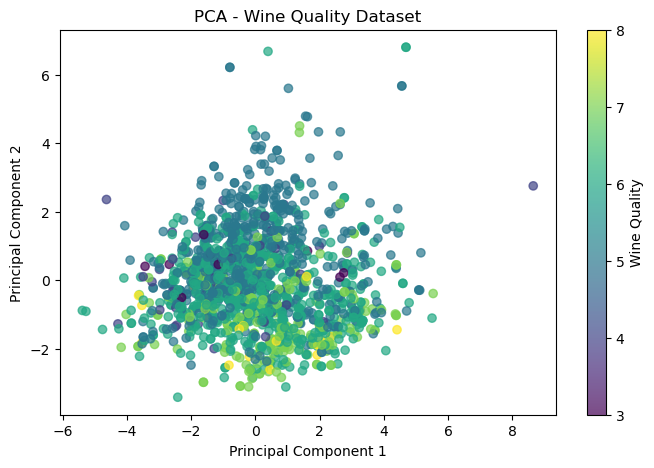

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df= pd.read_csv(r"C:\Users\user\Downloads\archive (15)\winequality-red.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

X = df.drop("quality",axis=1)
y = df["quality"]

normalizer=MinMaxScaler()
X_normalizer = normalizer.fit_transform(X)

print("\nNormalized data (first 5 rows):")
print(pd.DataFrame(
    X_normalizer, columns=X.columns).head().round(3))

standardizer = StandardScaler()
X_standardized =standardizer.fit_transform(X)

print("\nStandardized data (first 5 rows):")
print(pd.DataFrame(
    X_standardized, columns=X.columns).head().round(3))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA output (first 5 rows:)")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))

print("\nOriginal number of features:",X.shape[1])
print("Reduced number of features:",X_pca.shape[1])

print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("Total variance retained:",round(sum(pca.explained_variance_ratio_)*100,2),"%")

plt.figure(figsize=(8,5))
plt.scatter(X_pca[:,0], X_pca[:,1],c=y, cmap="viridis", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()